# EDA - BraTS 2020 HDF5

Ce notebook explore la version Kaggle prétraitée en coupes 2D. Chaque fichier HDF5 contient `image` (240x240x4) et `mask` (240x240x3).

In [4]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path("../data/raw/data")
FIGURE_ROOT = Path("../results/figures/eda_h5")
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
files = sorted(DATA_ROOT.rglob("*.h5"))
if not files:
    raise FileNotFoundError(f"Aucun fichier HDF5 dans {DATA_ROOT.resolve()}")
print(f"Fichiers HDF5: {len(files)}")

Fichiers HDF5: 57195


In [5]:
records = []
for path in files:
    with h5py.File(path, "r") as handle:
        image = handle["image"]
        mask = handle["mask"]
        records.append({"file": path.name, "image_shape": image.shape, "mask_shape": mask.shape, "image_dtype": str(image.dtype), "mask_dtype": str(mask.dtype), "tumor_fraction": float(np.count_nonzero(mask) / mask.size)})
table = pd.DataFrame(records)
display(table.head())
display(table.describe(include="all"))
table.to_csv(FIGURE_ROOT / "h5_summary.csv", index=False)

,file,image_shape,mask_shape,image_dtype,mask_dtype,tumor_fraction
0,volume_100_slice_0.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,0.000000
1,volume_100_slice_1.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,0.000000
2,volume_100_slice_10.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,0.000000
3,volume_100_slice_100.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,0.006429
4,volume_100_slice_101.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,0.006146


,file,image_shape,mask_shape,image_dtype,mask_dtype,tumor_fraction
count,57195,57195,57195,57195,57195,57195.000000
unique,57195,1,1,1,1,NaN
top,volume_100_slice_0.h5,"(240, 240, 4)","(240, 240, 3)",float64,uint8,NaN
freq,1,57195,57195,57195,57195,NaN
mean,NaN,NaN,NaN,NaN,NaN,0.003717
std,NaN,NaN,NaN,NaN,NaN,0.006279
min,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,0.005723


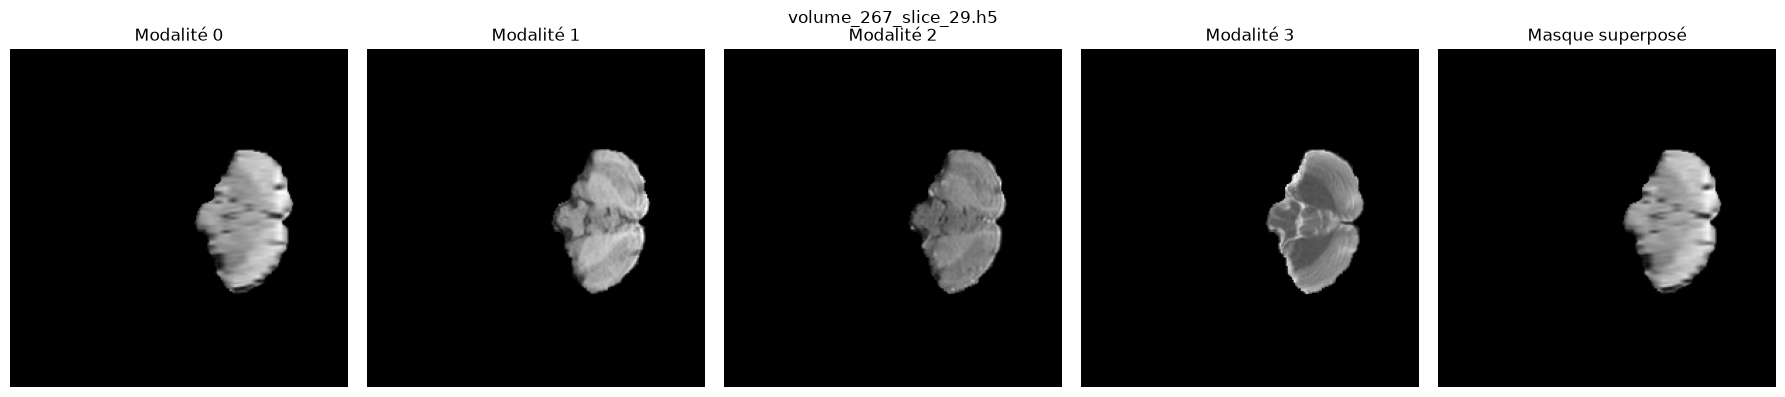

In [6]:
sample = files[len(files) // 2]
with h5py.File(sample, "r") as handle:
    image = handle["image"][:]
    mask = handle["mask"][:]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for index in range(4):
    axes[index].imshow(image[:, :, index], cmap="gray")
    axes[index].set_title(f"Modalité {index}")
    axes[index].axis("off")
axes[4].imshow(image[:, :, 0], cmap="gray")
axes[4].imshow(np.ma.masked_where(mask.sum(axis=2) == 0, mask.sum(axis=2)), cmap="autumn", alpha=0.55)
axes[4].set_title("Masque superposé")
axes[4].axis("off")
fig.suptitle(sample.name)
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "sample_slice.png", dpi=150)
plt.show()

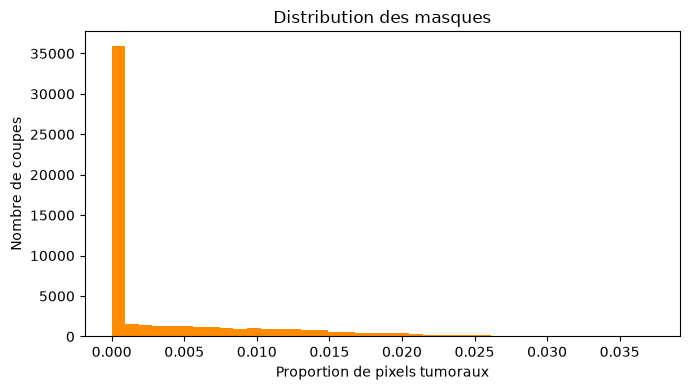

In [7]:
fig, axis = plt.subplots(figsize=(7, 4))
axis.hist(table["tumor_fraction"], bins=40, color="darkorange")
axis.set_xlabel("Proportion de pixels tumoraux")
axis.set_ylabel("Nombre de coupes")
axis.set_title("Distribution des masques")
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "tumor_fraction.png", dpi=150)
plt.show()